# Naive Bayes classifiers on Weather dataset

Naive Bayes classification is a probabilistic approach for classification. It is based on Bayes Theorem with the "naive" assumption that features are conditionally independent given the class:

$$P(y \mid x_1,\dots,x_n) \propto P(y)\prod_{i=1}^n P(x_i \mid y)$$

The way $P(x_i \mid y)$ is modelled gives the different variants: **Categorical** (counts per category, with Laplace smoothing), Gaussian, Multinomial, Bernoulli.

All features of the weather data are *categorical*, so `CategoricalNB` is the variant that matches the textbook calculation. Gaussian / Bernoulli / Multinomial are shown only for comparison: they treat the label-encoded integers as real numbers / counts / binary flags, which is not meaningful for this data.

## 1. Import the libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Prepare the Dataset

The dataset is based on the following.
(the classic 14-row *play tennis* table, entered as Python lists below)

In [2]:
# Convert the above data into Python lists. The ordering in the above data is followed.

Outlook = ['sunny' ,'sunny', 'overcast', 'rainy', 'rainy', 'rainy', 'overcast',
           'sunny', 'sunny', 'rainy', 'sunny', 'overcast', 'overcast', 'rainy']

Temp = ['hot', 'hot', 'hot', 'mild', 'cool', 'cool', 'cool', 'mild', 'cool',
       'mild','mild','mild','hot','mild']

Humidity = ['high', 'high', 'high', 'high', 'normal', 'normal', 'normal', 'high',
           'normal','normal','normal' , 'high', 'normal', 'high']

Windy = ['false' ,'true' ,'false' ,'false' ,'false' ,'true' ,'true' ,'false' ,
         'false' ,'false' ,'true' ,'true' ,'false' ,'true' ]

Play = ['no','no','yes','yes','yes','no','yes','no',
        'yes','yes','yes','yes','yes','no']


In [3]:
# create a dataframe from the above lists.

weatherdata = pd.DataFrame(
    {'Outlook': Outlook,
     'Temp': Temp,
     'Humidity': Humidity,
     'Windy': Windy,
     'Play': Play
    })
print(weatherdata.head())

    Outlook  Temp Humidity  Windy Play
0     sunny   hot     high  false   no
1     sunny   hot     high   true   no
2  overcast   hot     high  false  yes
3     rainy  mild     high  false  yes
4     rainy  cool   normal  false  yes


In [4]:
# Encode the list as 0,1,2,...

from sklearn import preprocessing

le = preprocessing.LabelEncoder()

# apply the label encoder for each list
outlook = le.fit_transform(Outlook)      # 2,2,0,1,1
temp = le.fit_transform(Temp)            # 1,1,1,2,0
humidity = le.fit_transform(Humidity)    # 0,0,0,0,1
windy = le.fit_transform(Windy)          # 0,1,0,0,0
play = le.fit_transform(Play)            # 0,0,1,1,1


# create a dataframe from the encoded lists.
weatherFeatures = pd.DataFrame(
    {'outlook': outlook,
     'temp': temp,
     'humidity': humidity,
     'windy': windy,
    })
print(weatherFeatures.head())

print('Play = ', play)

   outlook  temp  humidity  windy
0        2     1         0      0
1        2     1         0      1
2        0     1         0      0
3        1     2         0      0
4        1     0         1      0
Play =  [0 0 1 1 1 0 1 0 1 1 1 1 1 0]


## Visualize the dataset

In [5]:
data2d = weatherFeatures.loc[:,['outlook','windy']]

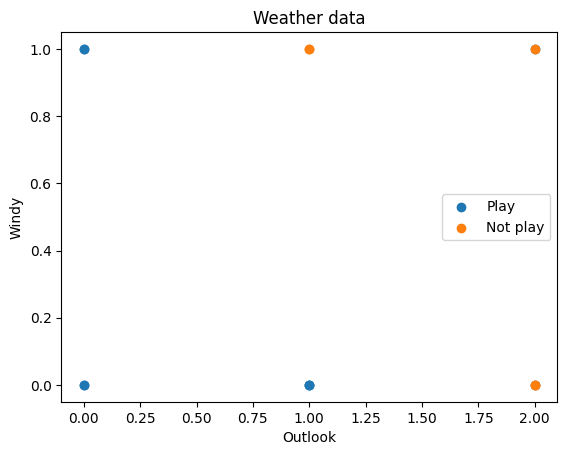

In [6]:
pos = data2d.loc[play == 1]
neg = data2d.loc[play == 0]

plt.scatter(pos.iloc[:, 0], pos.iloc[:, 1], label='Play')
plt.scatter(neg.iloc[:, 0], neg.iloc[:, 1],  label='Not play')

plt.xlabel('Outlook')
plt.ylabel('Windy')
plt.title('Weather data')
plt.legend()
plt.show()



## 3. Build the classifier  
## 4. Make predictions for new Data

In [7]:
from sklearn.naive_bayes import CategoricalNB
# CategoricalNB models each feature as a categorical distribution with Laplace smoothing (alpha=1)
cnb = CategoricalNB(alpha=1.0)
# train the classifier
cnb.fit(weatherFeatures, play)
# predict for training data
predicted = cnb.predict(weatherFeatures)  ## input to predict is the entire training dataset itself
print("Predicted Value for training data:", predicted)
# predict for new data: 0:overcast, 2:mild, 1:normal, 1:true  (a DataFrame, so feature names match)
new_x = pd.DataFrame([[0, 2, 1, 1]], columns=weatherFeatures.columns)
print("Predicted Value for new data:", cnb.predict(new_x))
print("sklearn  P(no), P(yes):", cnb.predict_proba(new_x).round(4)[0])

Predicted Value for training data: [0 0 1 1 1 1 1 0 1 1 1 1 1 0]
Predicted Value for new data: [1]
sklearn  P(no), P(yes): [0.0957 0.9043]


In [8]:
# The same calculation BY HAND on the original string data: counts + Laplace smoothing (alpha = 1)
#   P(x_i = v | y) = (count(v, y) + 1) / (count(y) + number_of_categories_of_feature_i)
new = {'Outlook': 'overcast', 'Temp': 'mild', 'Humidity': 'normal', 'Windy': 'true'}
scores = {}
for c in ['no', 'yes']:
    rows = weatherdata[weatherdata.Play == c]
    p = len(rows) / len(weatherdata)                       # prior P(y)
    for col, v in new.items():
        k = weatherdata[col].nunique()                     # categories of this feature
        p *= ((rows[col] == v).sum() + 1) / (len(rows) + k)  # smoothed likelihood
    scores[c] = p                                          # unnormalised posterior
total = sum(scores.values())
print('by hand  P(no), P(yes):', [round(float(scores[c] / total), 4) for c in ['no', 'yes']])

by hand  P(no), P(yes): [0.0957, 0.9043]


In [9]:
from sklearn.naive_bayes import GaussianNB

# For comparison only: GaussianNB treats the encoded integers as real numbers
# create an object of the GaussianNB classifier
gnb_classifier = GaussianNB()

# train the classifier
gnb_classifier.fit(weatherFeatures, play)


# predict for training data
predicted= gnb_classifier.predict(weatherFeatures)  ## input to predict is entire training dataset itself
print("Predicted Value for training data:", predicted)

# predict for new data # 0:overcast, 2:mild, 1:normal, 1:true
y= gnb_classifier.predict(new_x)
print("Predicted Value for new data:", y)


Predicted Value for training data: [0 0 1 1 1 1 1 0 1 1 1 1 1 0]
Predicted Value for new data: [1]


In [10]:
from sklearn.naive_bayes import BernoulliNB

# For comparison only: BernoulliNB binarises the features (value > 0)
# create an object of the BernoulliNB classifier
bnb = BernoulliNB()

# train the classifier
bnb.fit(weatherFeatures, play)


# predict for training data
predicted= bnb.predict(weatherFeatures)
print("Predicted Value for training data:", predicted)


# predict for new data # 0:overcast, 2:mild, 1:normal, 1:true
y= bnb.predict(new_x)
print("Predicted Value for new data:", y)


Predicted Value for training data: [0 0 1 0 1 1 1 0 1 1 1 1 1 0]
Predicted Value for new data: [1]


In [11]:
from sklearn.naive_bayes import MultinomialNB

# For comparison only: MultinomialNB treats the encoded integers as counts
mnb = MultinomialNB()

# train the classifier
mnb.fit(weatherFeatures, play)


# predict for training data
predicted= mnb.predict(weatherFeatures)
print("Predicted Value for training data:", predicted)


# predict for new data # 0:overcast, 2:mild, 1:normal, 1:true
y= mnb.predict(new_x)
print("Predicted Value for new data:", y)


Predicted Value for training data: [0 0 1 1 1 1 1 1 1 1 1 1 1 1]
Predicted Value for new data: [1]


## 5. Performance Measures

In [12]:
# display the accuracy -- on the TRAINING data (there are only 14 rows, no separate test set)
print('Training accuracy')
print('CategoricalNB  = ', cnb.score(weatherFeatures, play)*100 )
print('GaussianNB     = ', gnb_classifier.score(weatherFeatures, play)*100 )
print('BernoulliNB    = ', bnb.score(weatherFeatures, play)*100 )
print('MultinomialNB  = ', mnb.score(weatherFeatures, play)*100 )

# A more honest estimate with so few rows: leave-one-out cross-validation
from sklearn.model_selection import cross_val_score, LeaveOneOut
print()
print('Leave-one-out accuracy')
for name, clf in [('CategoricalNB', CategoricalNB()), ('GaussianNB', GaussianNB()),
                  ('BernoulliNB', BernoulliNB()), ('MultinomialNB', MultinomialNB())]:
    print('%-14s = %.1f' % (name, cross_val_score(clf, weatherFeatures, play, cv=LeaveOneOut()).mean() * 100))

Training accuracy
CategoricalNB  =  92.85714285714286
GaussianNB     =  92.85714285714286
BernoulliNB    =  85.71428571428571
MultinomialNB  =  78.57142857142857

Leave-one-out accuracy
CategoricalNB  = 50.0
GaussianNB     = 64.3
BernoulliNB    = 57.1
MultinomialNB  = 71.4


## 6. Visualize the decision boundary

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but GaussianNB was fitted with feature names
  warnings.warn(


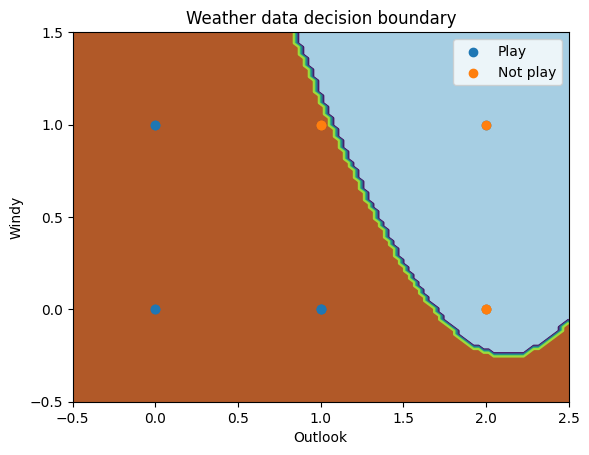

In [13]:
# Visualize  the classifier (a 2-feature GaussianNB on outlook and windy only; the models above use all 4 features)
# get min / max of both axes
x_min, x_max = data2d.iloc[:, 0].min() - .5, data2d.iloc[:, 0].max() + .5
y_min, y_max = data2d.iloc[:, 1].min() - .5, data2d.iloc[:, 1].max() + .5
# create a meshgrid
xx, yy  = np.meshgrid(np.linspace(x_min, x_max, num=100), np.linspace(y_min, y_max, num=100))
gnb = GaussianNB()
gnb.fit(data2d,play)
# predict for the meshgrid
z = gnb.predict( np.c_[xx.ravel(), yy.ravel()] )
z = z.reshape(xx.shape)
# plot the meshgrid
plt.pcolormesh(xx, yy, z, cmap=plt.cm.Paired)
# plot decision boundary
plt.contour(xx, yy, z)
# plot the dataset
plt.scatter(pos.iloc[:, 0], pos.iloc[:, 1], label='Play')
plt.scatter(neg.iloc[:, 0], neg.iloc[:, 1],  label='Not play')
plt.xlabel('Outlook')
plt.ylabel('Windy')
plt.xticks(np.arange(-0.5, 2.6, step=0.5))
plt.yticks(np.arange(-0.5, 2.6, step=0.5))
plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.title('Weather data decision boundary')
plt.legend()
plt.show()